# Removing the pair-mass confounding from the 2μ2e ABCD estimate

**Summary.** `nominal.ipynb` estimates the 2μ2e background in the search region as the search
plane's own A = B·C/D = 45.7 events. That estimate assumes that the two variables defining the
regions, the muon lepton jet's isolation and the azimuthal angle |Δφ| between the two lepton jets, are
independent for the background. Their pass probabilities can change with the lepton-jet pair mass
M, and when both change, a single ABCD over all masses mixes populations: summed over
mass bins, the same estimate reads 1.62 times the one-bin value with two windows (split at
300 GeV) and 2.06 with the five bins of the histograms (1.03 and 1.04 in PP,
1.01 and 1.01 in PD). In the search plane this rests on one bin: at 300–400 GeV, C/D =
5/1, and one more event in D there would bring the five-bin factor from 2.06 to
1.39. The search plane's isolation pass probability against M is compatible with PD's shape
(χ² = 5.1/3, p = 0.16 (p = 0.17 from toys)) and with PP's (χ² = 4.4/3, p = 0.22 (p = 0.24 from toys)).

This notebook tries three ways of removing the mixing and compares them by the simplicity of the
analysis they lead to, systematics included: (1) stratify, estimating the background separately in
each mass bin; (2) fit the isolation pass probability with a smooth function of M and apply it to
B's mass spectrum; (3) choose the isolation cut per mass bin so that its pass probability is flat in
M. In two windows, route 1 gives 74.0 events (68% interval 47–155), with a closure systematic
by the rule of `nominal.ipynb` in each window (31% and 34%); in five bins it gives
94.0 and the rule has no qualifying region in 300-400 and ≥ 400. Route 2 gives 72.1 with the search
plane's own slope and 45.8 with PD's. Route 3 cannot flatten the search plane: its 300–400 GeV
bin reads a = 0.80–0.83 at every stored edge, and the mixing factor stays at 1.92 (1.06–2.20). In every
route PD's closure stays at 1.16–1.21: PD's non-closure, which sets the 20% systematic of
`nominal.ipynb`, is not mass mixing (PD's mixing factor is 1.01), although PD's κ does change
with the mass (1.31 ± 0.12 below 300 GeV, 0.87 ± 0.17 above). The open bands of the search plane have no
C or D event above 300 GeV and cannot test the rise. Section 5 proposes route 1 in two windows.

**How to read this notebook.** Every number is from data unless it is marked as simulation. The
search region (region A of the search plane above 150 GeV) is hidden: the histograms are loaded with
those cells set to NaN, a region that touches them prints as "hidden" or NaN, and no estimate uses
them. Section 1 states the problem and measures it, sections 2–4 try the three routes, section 5
compares them and makes the proposal. Terms defined in `nominal.ipynb` (lepton jet, the planes PP,
PD, DP and DD, the regions A–D, κ, the working point, the closure systematic's rule) are repeated
briefly where they are first used.

In [1]:
import dataclasses
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import abcd6d_io as io
import transfer_lib as tl
import transfer_plots as tp
import plane_search_lib as ps
import binning_lib as bl
import nominal_lib as nl
import decorrelation_lib as dl
import decorrelation_plots as dp

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 120)
tp.set_style()

BASE = os.environ.get("ABCD8D_LOCAL", "/uscms_data/d3/murtazas/abcd8d_local")
print("8D inputs:", BASE)
data = tl.summed_cubes(BASE, "data", prefix="abcd8d")     # the only data path: hidden cells are NaN
print("hidden box:", io.blind_signature(prefix="abcd8d"))
d2 = data["2mu2e"]
print(f"2mu2e: {d2.sumw.shape}, {int(np.isnan(d2.sumw).sum())} hidden cells")
NOMINAL = dl.NOMINAL
print("working point:", NOMINAL.label())
print("mass bins:", [label for label, _ in dl.FIVE], "; windows:", [label for label, _ in dl.TWO])
print("bootstrap toys:", dl.N_TOYS, "seed", dl.SEED)

8D inputs: /uscms_data/d3/murtazas/abcd8d_local


hidden box: iso0<0.25 iso1<0.5 mass>=150 dphi>=2.4 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]
2mu2e: (12, 12, 6, 4, 10, 10, 8, 3), 241920 hidden cells
working point: dphi 2.4/2.4 x iso0 0.25/0.25, iso1<0.5, M>=150
mass bins: ['150-200', '200-300', '300-400', '400-600', '>=600'] ; windows: ['150-300', '>=300']
bootstrap toys: 40000 seed 20261016


## 1. The problem: the pair mass as a third variable

**The ABCD method in one paragraph.** Two cuts split a plane into four regions: A passes both
(the search region), B fails the isolation cut and passes |Δφ|, C passes the isolation cut and fails
|Δφ|, D fails both. Here the isolation cut is "muon-LJ isolation < 0.25" and the |Δφ| cut
"|Δφ| ≥ 2.4"; the egamma lepton jet is isolated (< 0.5) and M ≥ 150 GeV. If the two cuts are
independent for the background, A = B·C/D. Where A is open, the closure ratio κ = A·D/(B·C)
tests that; κ = 1 means the method works there. The planes are named by the displacement of the muon
lepton jet and then of the egamma lepton jet (P prompt, D displaced): DD is the search plane, PP and
PD are open planes with a prompt muon lepton jet whose A can be looked at.

**Why the mass matters.** Split the events into mass bins w. In bin w let n_w be the number of
background events, a_w the probability that an event passes the isolation cut and b_w the
probability that it passes the |Δφ| cut. If the two cuts are independent within each bin,

* A_w = n_w a_w b_w, B_w = n_w (1 − a_w) b_w, C_w = n_w a_w (1 − b_w), D_w = n_w (1 − a_w)(1 − b_w),

so A_w = B_w C_w / D_w holds bin by bin, and the true A is A = Σ_w n_w a_w b_w = Σ_w B_w C_w / D_w.
The one-bin estimate instead uses the sums, (Σ B)(Σ C)/(Σ D). Write r_w = a_w/(1 − a_w) = C_w/D_w
for the isolation **odds** (pass over fail) and β_w = b_w/(1 − b_w) = B_w/D_w for the |Δφ| odds. Then
B_w = β_w D_w and C_w = r_w D_w, and

* Σ_w B_w C_w / D_w = Σ_w D_w β_w r_w, while (Σ B)(Σ C)/(Σ D) = (Σ_w D_w β_w)(Σ_w D_w r_w)/(Σ_w D_w).

If r_w = r is the same in every bin, both are r Σ_w D_w β_w; if β_w = β is the same in every bin,
both are β Σ_w D_w r_w. So **the one-bin estimate is exact when either a(M) or b(M) is constant in
M**, whatever the other does. When both vary, the ratio of the two is the **mixing factor**

* m = Σ_w B_w C_w / D_w ÷ (B·C/D) = ⟨β r⟩_D / (⟨β⟩_D ⟨r⟩_D) = 1 + cov_D(β, r) / (⟨β⟩_D ⟨r⟩_D),

where ⟨·⟩_D is the average over the bins weighted by D_w and cov_D the covariance with the same
weights. If the cuts are independent within each bin, the one-bin κ equals m: the one-bin estimate is
low by m when the two odds rise (or fall) together with M, and high when one rises while the other
falls. In data m is computed from B, C and D alone, so it can be measured in the search plane without
opening A.

The table below checks this on four synthetic populations of five mass bins, with exact expected
counts: with a flat a(M) or a flat b(M) the one-bin estimate equals the true A, with both rising it
is low (m = 1.096), with opposite trends high (m = 0.911), and the covariance form gives
the same number as the ratio.

In [2]:
display(dl.synthetic_table().round(3))

,population,true A,one-bin B C/D,sum over bins of B C/D,mixing factor,"1 + cov_D(beta, r)/(<beta><r>)",A / one-bin
0,"a flat, b rising",242.55,242.550,242.55,1.000,1.000,1.000
1,"a rising, b flat",250.38,250.380,250.38,1.000,1.000,1.000
2,both rising,250.50,228.544,250.50,1.096,1.096,1.096
3,"a falling, b rising",358.95,394.211,358.95,0.911,0.911,0.911


### 1a. a(M) and b(M) in the data

Per plane and mass bin, a = C/(C + D) is the isolation pass probability among the events that fail
|Δφ|, and b = B/(B + D) the |Δφ| pass probability among the events that fail the isolation; both use
only B, C and D, so in DD above 150 GeV both are open. The intervals are 68% **Clopper–Pearson**
intervals (the exact binomial interval, which stays inside [0, 1] for small counts). In the five
bins 150–200, 200–300, 300–400, 400–600 and ≥ 600 GeV:

* PP: a = 0.32, 0.35, 0.40, 0.38, 0.43; b = 0.75, 0.81, 0.86, 0.85, 0.92 (B/C/D 518/82/171; 575/73/136; 272/29/44; 133/15/24; 47/3/4);
* PD: a = 0.46, 0.40, 0.51, 0.37, 0.69; b = 0.73, 0.77, 0.83, 0.78, 0.84 (B/C/D 530/171/199; 519/105/155; 211/43/42; 120/19/33; 21/9/4);
* DD: a = 0.27, 0.33, 0.83, 0.33, n/a; b = 0.64, 0.71, 0.93, 0.82, 1.00 (B/C/D 28/6/16; 24/5/10; 13/5/1; 9/1/2; 4/0/0).

b rises with M in all three planes. a rises slowly in PP, has no trend in PD, and in DD jumps at
300–400 GeV to 0.83 -0.29 +0.14, from C/D = 5/1; the ≥ 600 GeV bin of DD has B/C/D = 4/0/0, so its a
is undefined. Is DD's a(M) PD's shape? Scaling PD's a(M) to DD's mean (the factor that makes the
expected C of DD sum to the observed, 0.84) and comparing bin by bin with binomial errors of both
planes gives χ² = 5.1/3, p = 0.16 (p = 0.17 from toys), over the bins where DD has events; against PP's shape χ² = 4.4/3, p = 0.22 (p = 0.24 from toys). The
largest deviation in both is the 300–400 GeV bin (pull +2.0 against PD, +1.9 against
PP). DD's a(M) is therefore compatible with the flat or slowly rising shape of the open planes; the
rise it shows rests on that one bin.

*How to read the figure:* left a(M), right b(M), per plane (PP black, PD blue, DD green), points at
the geometric centres of the bins (the ≥ 600 GeV bin at 775 GeV), shifted slightly sideways per
plane; error bars are the 68% intervals.

,plane,bin,A,B/C/D,a = C/(C+D),b = B/(B+D)
0,PP,150-200,292,518/82/171,0.32 ± 0.03,0.75 ± 0.02
1,PP,200-300,306,575/73/136,0.35 ± 0.04,0.81 -0.02 +0.01
2,PP,300-400,121,272/29/44,0.40 ± 0.07,0.86 -0.02 +0.02
3,PP,400-600,52,133/15/24,0.38 -0.09 +0.09,0.85 -0.03 +0.03
4,PP,>=600,26,47/3/4,0.43 -0.22 +0.25,0.92 -0.06 +0.04
5,PD,150-200,574,530/171/199,0.46 ± 0.03,0.73 ± 0.02
6,PD,200-300,494,519/105/155,0.40 ± 0.03,0.77 -0.02 +0.02
7,PD,300-400,171,211/43/42,0.51 ± 0.06,0.83 -0.03 +0.02
8,PD,400-600,79,120/19/33,0.37 -0.07 +0.08,0.78 -0.04 +0.03
9,PD,>=600,25,21/9/4,0.69 -0.18 +0.14,0.84 -0.11 +0.07


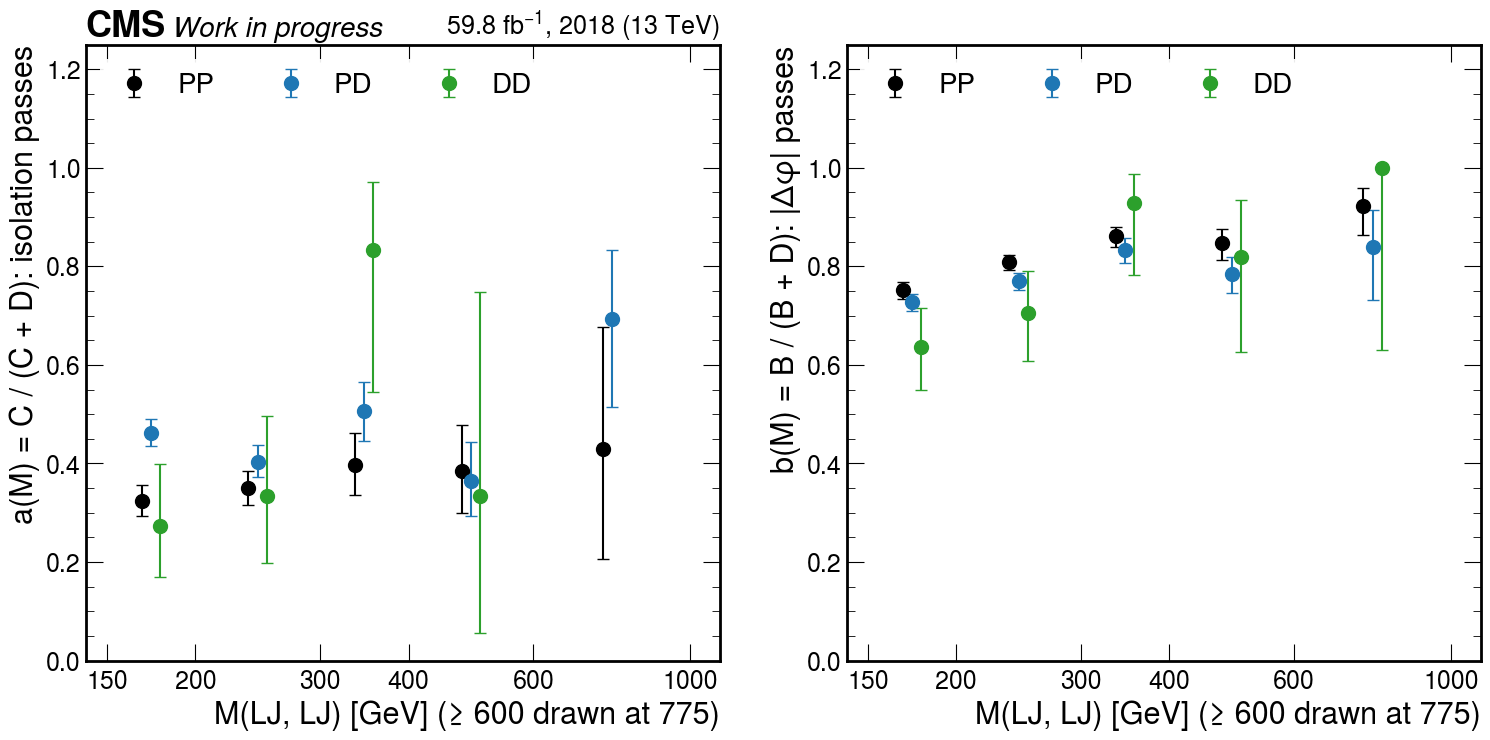

In [3]:
PASS = dl.pass_table(d2, NOMINAL)
display(dl.pass_view(PASS))
fig = dp.pass_figure(PASS)

### 1b. The mass spectra of B, C and D

The mixing factor depends on how the regions spread over the mass: the shares of B/C/D above
300 GeV are 29%/23%/19% in PP, 25%/20%/18% in PD and 33%/35%/10% in DD. DD's C sits at higher
mass than its D, PP's and PD's do not by much.

*How to read the figure:* one panel per plane; each region's mass spectrum is normalised to one over
the five bins (B purple, C orange, D cyan, the total count in brackets); error bars are √n over the
region's total.

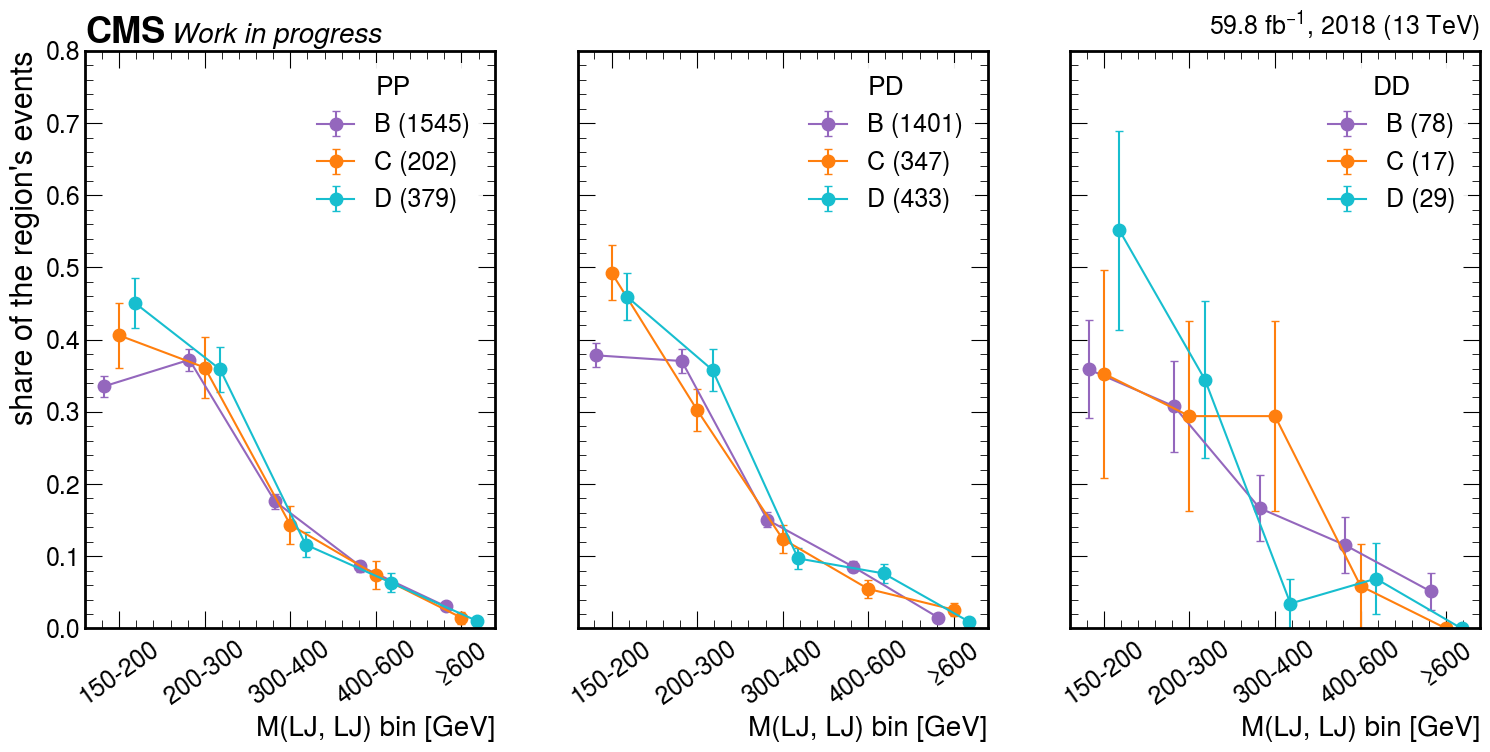

In [4]:
SPECTRA = dl.spectra_table(d2, NOMINAL)
fig = dp.spectra_figure(SPECTRA)

### 1c. The mixing factor

The mixing factor per plane with five bins, two windows (split at 300 GeV) and one bin (one by
definition). A bin whose D is empty has no B·C/D; it is merged into the bin below (in DD the
≥ 600 GeV bin, so DD's five-bin factor is computed over 150-200, 200-300, 300-400, ≥ 400). The intervals are from a
**Poisson bootstrap**: each B, C and D is redrawn 40000 times from a Poisson distribution whose
mean is the observed count, the factor is recomputed, and the 16th and 84th percentiles over all toys
are quoted; no toy is dropped. Each toy follows the procedure of its binning: the five-bin procedure
merges a bin with an empty D (its data path merges DD's ≥ 600 GeV bin), so its toys merge the same
way, while the two windows have no merge rule (no window of the data is empty), so a toy with no D
event in a window has no estimate and counts as above every other toy, as in `nominal.ipynb`
section 7d.

* PP: 1.04 with five bins (1.02–1.11), 1.03 with two windows (1.00–1.06);
* PD: 1.01 (1.00–1.07) and 1.01 (1.00–1.03);
* DD: 2.06 (1.08–2.35, below one in 8% of the toys) and 1.62 (1.16–3.13,
  below one in 3%; 95% of the toys have a finite factor, the rest drew no D
  event above 300 GeV, a chance of 5%).

The open planes mix by 1–4%. In DD the two windows have C/D = 0.42 and 2.00: the summed estimate is
74.0 events with two windows and 94.0 with five, against 45.7 in one bin. **What
the mixing in DD rests on:** the 300–400 GeV bin, C/D = 5/1. With one more event in D of that
bin the five-bin factor would be 1.39 (one more D in each of the other bins in turn:
2.11, 2.10, 2.08); with one more event in D above 300 GeV the two-window factor would be 1.38
(D = 3 there now). The factor in DD is real if DD's a(M) rises as its four filled bins say, and
an accident of one event if it has the open planes' shape, which section 1a cannot exclude.

In [5]:
MIX = dl.mixing_table(d2, NOMINAL)
display(dl.mixing_view(MIX))
for plane in dl.PLANES:
    m = dl.mixing_factor(d2, NOMINAL, plane, dl.FIVE)
    labels = [label for label, _ in m["bins"]]
    print(f"{plane}: five-bin factor with one more D event in ...", ", ".join(f"{labels[i]}: {v:.2f}" for i, v in dl.mixing_sensitivity(m["windows"])))
CD = {p: PASS.loc[PASS["plane"] == p, ["C", "D"]].to_numpy() for p in dl.PLANES}
for ref in ("PD", "PP"):
    st = dl.shape_test(CD["DD"], CD[ref])
    print(f"DD's a(M) against {ref}'s shape: chi2 {st['chi2']:.1f}/{st['ndf']}, p = {st['p']:.2f} (toys {st['p_toys']:.2f}), "
          f"scale {st['k']:.2f}, pulls", np.round(st["pulls"], 1))

,plane,binning,bins used,sum of B C/D,one-bin B C/D,mixing factor,bootstrap 16/50/84%,toys below 1,toys with a finite factor
0,PP,5 bins,"150-200, 200-300, 300-400, 400-600, >=600",854.7,823.5,1.04,1.02/1.05/1.11,6%,100%
1,PP,2 windows,"150-300, >=300",846.9,823.5,1.03,1.00/1.03/1.06,12%,100%
2,PP,1 bin,>=150,823.5,823.5,1.00,,,100%
3,PD,5 bins,"150-200, 200-300, 300-400, 400-600, >=600",1139.4,1122.7,1.01,1.00/1.03/1.07,16%,100%
4,PD,2 windows,"150-300, >=300",1134.2,1122.7,1.01,1.00/1.01/1.03,22%,100%
5,PD,1 bin,>=150,1122.7,1122.7,1.00,,,100%
6,DD,5 bins,"150-200, 200-300, 300-400, >=400",94.0,45.7,2.06,1.08/1.46/2.35,8%,100%
7,DD,2 windows,"150-300, >=300",74.0,45.7,1.62,1.16/1.63/3.13,3%,95%
8,DD,1 bin,>=150,45.7,45.7,1.00,,,100%


PP: five-bin factor with one more D event in ... 150-200: 1.04, 200-300: 1.04, 300-400: 1.04, 400-600: 1.04, >=600: 1.03
PD: five-bin factor with one more D event in ... 150-200: 1.02, 200-300: 1.02, 300-400: 1.01, 400-600: 1.02, >=600: 1.01
DD: five-bin factor with one more D event in ... 150-200: 2.11, 200-300: 2.10, 300-400: 1.39, >=400: 2.08
DD's a(M) against PD's shape: chi2 5.1/3, p = 0.16 (toys 0.17), scale 0.84, pulls [-1.1 -0.   2.   0.1]
DD's a(M) against PP's shape: chi2 4.4/3, p = 0.22 (toys 0.24), scale 1.07, pulls [-0.7 -0.3  1.9 -0.3]


### 1d. An open region with both lepton jets displaced above 300 GeV

The search plane has open regions above 150 GeV: the bands where the egamma lepton jet is not
isolated (egamma-LJ isolation ≥ 0.5, ≥ 0.75, ≥ 1 and 0.5–1). Their A is open, because the hidden box
ends at egamma-LJ isolation 0.5, and they have both lepton jets displaced. Could they show whether
DD's a(M) rises? The widest band, egamma-LJ isolation ≥ 0.5, holds B/C/D = 24/6/6 in 150–300 GeV and 6/0/0 above 300 GeV; the
bands ≥ 0.75, ≥ 1, 0.5–1 lie inside it. Its a = C/(C + D) is 0.50 ± 0.18 in 150–300 GeV, against
0.30 -0.08 +0.09 for DD and 0.44 ± 0.02 for PD, and above 300 GeV it has C + D = 0, so a is
undefined there. In the five bins its a is 0.57, 0.40, n/a, n/a, n/a; against DD's shape it gives χ² = 0.5/1, p = 0.48
and against PD's χ² = 0.1/1, p = 0.72, over the 2 bins where it has events, both below 300 GeV.
**The open bands cannot test the rise:** none has a C or D event above 300 GeV.

What the search plane's own sidebands show is the window-to-window change of the isolation odds:
ln(r above 300 GeV / r in 150–300 GeV) is 1.55 ± 0.79 in DD (a factor 4.7) and 0.14 ± 0.18 in PD (a
factor 1.2), a difference of 1.7 standard deviations (first-order errors, √(Σ 1/count)). The
separation grows as the square root of the data. If the central values held, it would reach two
standard deviations with 1.3 times the present data, about 4 D events above 300 GeV, and three
with 3.0 times, about 9 (now 3).

In [6]:
BAND = nl.dd_band_vrs()[0]
for name, bins in (("2 windows", dl.TWO), ("5 bins", dl.FIVE)):
    print(f"{BAND.name}, {name}:")
    display(dl.pass_view(dl.pass_table(d2, NOMINAL, [BAND], bins)))
CD_BAND = dl.pass_table(d2, NOMINAL, [BAND], dl.FIVE)[["C", "D"]].to_numpy()
for ref in ("DD", "PD"):
    st = dl.shape_test(CD_BAND, CD[ref])
    print(f"the band's a(M) against {ref}'s shape: chi2 {st['chi2']:.1f}/{st['ndf']}, {dl.fmt_p(st['p'])}, bins used {st['used']}")
PASS2 = dl.pass_table(d2, NOMINAL, ["PD", "DD"], dl.TWO)
CD2 = {p: PASS2.loc[PASS2["plane"] == p, ["C", "D"]].to_numpy() for p in ("PD", "DD")}
for p in ("PD", "DD"):
    print(f"{p}: log odds ratio between the windows", np.round(dl.log_odds_ratio(CD2[p]), 2))
print("DD against PD:", {k: round(v, 2) for k, v in dl.separation(CD2["DD"], CD2["PD"]).items()})

DD, egamma iso ≥ 0.5, 2 windows:


,plane,bin,A,B/C/D,a = C/(C+D),b = B/(B+D)
0,"DD, egamma iso ≥ 0.5",150-300,16,24/6/6,0.50 ± 0.18,0.80 -0.10 +0.08
1,"DD, egamma iso ≥ 0.5",>=300,4,6/0/0,n/a,1.00 -0.26 +0.00


DD, egamma iso ≥ 0.5, 5 bins:


,plane,bin,A,B/C/D,a = C/(C+D),b = B/(B+D)
0,"DD, egamma iso ≥ 0.5",150-200,8,13/4/3,0.57 -0.25 +0.22,0.81 -0.15 +0.10
1,"DD, egamma iso ≥ 0.5",200-300,8,11/2/3,0.40 -0.25 +0.30,0.79 -0.17 +0.11
2,"DD, egamma iso ≥ 0.5",300-400,3,2/0/0,n/a,1.00 -0.60 +0.00
3,"DD, egamma iso ≥ 0.5",400-600,0,3/0/0,n/a,1.00 -0.46 +0.00
4,"DD, egamma iso ≥ 0.5",>=600,1,1/0/0,n/a,1.00 -0.84 +0.00


the band's a(M) against DD's shape: chi2 0.5/1, p = 0.48, bins used [ True  True False False False]
the band's a(M) against PD's shape: chi2 0.1/1, p = 0.72, bins used [ True  True False False False]


PD: log odds ratio between the windows [0.14 0.18]
DD: log odds ratio between the windows [1.55 0.79]
DD against PD: {'diff': 1.41, 'err': 0.81, 'z': 1.73}


## 2. Route 1: stratify

The direct fix: estimate the background in each mass bin from that bin's own B, C and D and sum,
Σ_w B_w C_w / D_w. If the two cuts are independent within each bin this is exact, whatever a(M) and
b(M) do; what it needs instead is a validation of the method per bin. A mass-binned search region
needs per bin the background estimate, its closure κ in the open planes, and a closure systematic.

**κ per bin in the open planes** (reproducing `nominal.ipynb` section 7d): PP 1.18, 0.99, 0.67, 0.63, 0.74; PD 1.26, 1.41, 0.79, 1.14, 0.53
for the five bins.

**The estimate per bin.** The interval of each bin is over all toys of its own B, C and D, with no
upper bound where D is drawn as 0 often enough; the interval of the sum follows the convention of
section 1c (two windows: a toy with an empty D has no finite sum, 95% of the toys have
one; five bins: the merging is redone in each toy). With two windows: 150-300: 22.0 (14–32); ≥ 300: 52.0 (25–130); the sum is
**74.0 events** (bootstrap 68% interval 47–155, as in `nominal.ipynb` section 7d). With five bins (the ≥ 600 GeV bin merged with 400–600 GeV into ≥ 400 GeV, since its C and D
are empty): 150-200: 10.5 (6–17); 200-300: 12.0 (6–21); 300-400: 65.0 (24, no upper bound); ≥ 400: 6.5 (0–36); the sum is 94.0 events (43–114). The 300–400 GeV bin has D = 1 and is
drawn with D = 0 in 37% of the toys; those toys merge it with 200–300 GeV and land low, which is
why the sum's interval sits mostly below the central value. In all, 46% of the toys merge
more than the data do (beyond the ≥ 600 GeV bin), so the five-bin procedure falls back to fewer bins
that often. The five-bin sum over the
two-window one, 1.27, is the mixing that is left inside the windows, and it rests on the same
300–400 GeV bin.

**Closure of the summed estimate in the open planes**, A over Σ_w B_w C_w / D_w, with a bootstrap
interval: two windows PP 0.94 ± 0.10, PD 1.18 ± 0.10; five bins PP 0.93 -0.12 +0.09, PD 1.18 -0.12 +0.09 (one bin, from
the same bootstrap: PP 0.97 -0.09 +0.10, PD 1.20 -0.09 +0.10). Stratifying does not move PD towards one.

**The systematic per bin, by the rule of `nominal.ipynb` section 8:** among the validation regions
above 150 GeV, each restricted to the bin, those whose κ is measured to 20% or better (the larger
side of its 68% interval at most 20% of κ) and that are not a sub-population of a plane; the
systematic is the largest of |κ − 1| and the side of the interval facing one. The regions are PP,
PD and its egamma-type parts (PD split by whether the egamma lepton jet is a photon-only or an
electron lepton jet; as sub-populations of a plane they do not qualify), DP, the four
egamma-isolation bands of DD (section 1d), and Dongyub Lee's data validation regions above
150 GeV, V1, V5, V6 and V7, reproduced in `nominal.ipynb` from the same histograms (displacement of
the muon LJ / the egamma LJ, egamma-LJ isolation, mass: V1: P / P, egamma iso < 0.5, M ≥ 150 GeV; V5: P / any, egamma iso 0.2–1, M ≥ 150 GeV; V6: P / any, egamma iso 0.15–1, M ≥ 150 GeV; V7: P / P, egamma iso 0.15–1, M ≥ 150 GeV). Two windows: 150-300: 31% (PD); ≥ 300: 34% (V6); on the
sum, with the windows fully correlated, 33%. Full correlation is a choice: the regions
that set the two systematics pull in opposite directions (κ_PD is 1.31 ± 0.12 below 300 GeV and
0.87 ± 0.17 above), and a sum taken as uncorrelated would be smaller. Five bins:
150-200: 33% (V7); 200-300: 41% (PD); 300-400: no region qualifies; ≥ 400: no region qualifies. The regions that qualify, per bin: two windows 150-300: PD, PP, V1, V5, V6, V7; ≥ 300: PD, V5, V6; five bins 150-200: PD, PP, V1, V5, V6, V7; 200-300: PD, PP, V1, V5, V6, V7; 300-400: none; ≥ 400: none. So
in five bins the rule has no region in 300-400 and ≥ 400, and a five-bin search region would need an
assumed systematic there. In two windows the regions that qualify above 300 GeV are PD, V5, V6 (PD
with a precision of 19.6%).

The table under the code lists, per bin, what a mass-binned search region needs: the background with
its first-order error (the linear propagation of the Poisson errors of B, C and D,
B·C/D·√(1/B + 1/C + 1/D)) and its bootstrap interval, κ in PP and PD, and the systematic with the
regions that qualify.

In [7]:
KAPPA5 = bl.kappa_table(d2, NOMINAL, list(dl.FIVE), planes=dl.OPEN_PLANES)
display(KAPPA5[["plane", "bin", "A", "B", "C", "D", "kappa"]])
ST = {name: dl.stratified_table(d2, NOMINAL, bins) for name, bins in (("2 windows", dl.TWO), ("5 bins", dl.FIVE))}
for name, table in ST.items():
    print(f"route 1, {name} (toys with a finite sum: {100 * table.attrs['kept']:.0f}%)")
    display(dl.stratified_view(table))
for name, bins in (("2 windows", dl.TWO), ("5 bins", dl.FIVE), ("1 bin", dl.ONE)):
    print(f"closure of the summed estimate, {name}:",
          ", ".join(f"{p} {tl.fmt(dl.route_closure(d2, NOMINAL, p, bins), 2)}" for p in dl.OPEN_PLANES))

,plane,bin,A,B,C,D,kappa
0,PP,150-200,292,518,82,171,1.18 -0.18 +0.20
1,PP,200-300,306,575,73,136,0.99 -0.17 +0.18
2,PP,300-400,121,272,29,44,0.67 -0.19 +0.20
3,PP,400-600,52,133,15,24,0.63 -0.25 +0.29
4,PP,>=600,26,47,3,4,0.74 -0.74 +1.02
5,PP,all bins,,,,,0.97 ± 0.10; chi2/ndof of the bins against it 3.9 / 4
6,PD,150-200,574,530,171,199,1.26 ± 0.16
7,PD,200-300,494,519,105,155,1.41 ± 0.21
8,PD,300-400,171,211,43,42,0.79 ± 0.21
9,PD,400-600,79,120,19,33,1.14 -0.40 +0.44


route 1, 2 windows (toys with a finite sum: 95%)


,bin,B/C/D of DD,B C/D,bootstrap 68%,kappa PP,kappa PD,systematic (rule),regions measured to 20%
0,150-300,52/11/26,22.0 ± 8.5,14.1–31.6,1.08 ± 0.13,1.31 ± 0.12,31% (PD),"PD, PP, V1, V5, V6, V7"
1,>=300,26/6/3,52.0 ± 38.2,25.0–130.0,0.67 -0.15 +0.15,0.87 ± 0.17,34% (V6),"PD, V5, V6"
2,sum,78/17/29,74.0 ± 39.1,46.5–155.0,,,33%,


route 1, 5 bins (toys with a finite sum: 100%)


,bin,B/C/D of DD,B C/D,bootstrap 68%,kappa PP,kappa PD,systematic (rule),regions measured to 20%
0,150-200,28/6/16,10.5 ± 5.4,5.6–16.7,1.18 -0.18 +0.20,1.26 ± 0.16,33% (V7),"PD, PP, V1, V5, V6, V7"
1,200-300,24/5/10,12.0 ± 7.0,5.8–20.8,0.99 -0.17 +0.18,1.41 ± 0.21,41% (PD),"PD, PP, V1, V5, V6, V7"
2,300-400,13/5/1,65.0 ± 73.5,"24.0, no upper bound",0.67 -0.19 +0.20,0.79 ± 0.21,none qualifies,none
3,>=400,13/1/2,6.5 ± 8.2,0.0–36.0,0.67 -0.24 +0.27,0.97 -0.30 +0.31,none qualifies,none
4,sum,78/17/29,94.0 ± 74.4,43.1–114.4,,,none qualifies,


closure of the summed estimate, 2 windows: PP 0.94 ± 0.10, PD 1.18 ± 0.10


closure of the summed estimate, 5 bins: PP 0.93 -0.12 +0.09, PD 1.18 -0.12 +0.09
closure of the summed estimate, 1 bin: PP 0.97 -0.09 +0.10, PD 1.20 -0.09 +0.10


## 3. Route 2: a smooth transfer ratio

Instead of one ratio per bin, describe a(M) by a smooth function with few parameters, so that the
small bins borrow strength from the large ones. The function is a **logistic** in ln M,
a(M) = 1/(1 + exp(−(α + s·ln(M/200 GeV)))), equivalently the isolation odds
r(M) = a/(1 − a) = C/D = e^α (M/200 GeV)^s: α is the log-odds at 200 GeV and s the slope (s = 0 is a
flat a(M)). The fit is a binned maximum likelihood over the five bins: C_w out of C_w + D_w events
is a binomial count, which is the Poisson likelihood of C_w and D_w conditioned on their sum, so no
Gaussian approximation enters in the small bins. The bins sit at their geometric centres
(173, 245, 346, 490, 775 GeV; the ≥ 600 GeV bin as 600–1000 GeV). The estimate is then A_smooth = Σ_w B_w r(M_w).
Its interval is from the Poisson bootstrap, refitting α and s on each toy. The **deviance** is twice
the log-likelihood ratio of the fit against a free a per bin; for a good fit it is about its number
of degrees of freedom (bins − 2). Where it is larger, the data scatter about the curve more than
binomial counts would, and the fit's errors and the spread of its toys are scaled by
√(deviance/ndf). The rule is applied to every fit whose deviance/ndf exceeds one: here PD (factor 1.64), DD (factor 1.42) and DD's fit with PD's slope (factor 1.47).

* PP: α = -0.68 ± 0.10, s = 0.33 ± 0.26, deviance 0.2/3 (p = 0.98); Σ B r(M) = 852.3 (775–941) against
  A = 797, so κ_smooth = A/A_smooth = 0.94 ± 0.10;
* PD: α = -0.22 ± 0.13, s = 0.02 ± 0.34, deviance 8.1/3 (p = 0.04); Σ B r(M) = 1124.0 (997–1279) against
  A = 1343, κ_smooth = 1.19 -0.15 +0.16;
* DD: α = -0.75 ± 0.49, s = 1.53 ± 1.41, deviance 4.0/2 (p = 0.13); **A_smooth = 72.1 events** (39–308).

PD's deviance says the logistic does not describe PD's five bins well (its a(M) zigzags, and the
≥ 600 GeV bin sits high); PP is described. In DD the per-bin terms B_w r(M_w) are 10.6, 15.4, 14.2, 16.8, 15.0; the
last, 15.0, is B = 4 at ≥ 600 GeV times the fit's extrapolation r = 3.8 into a bin with no C
or D.

**Does the shape transfer?** The slopes: PP 0.33 ± 0.26, PD 0.02 ± 0.34, DD 1.53 ± 1.41. Against their weighted
mean χ² = 1.4/2 (p = 0.50); DD differs from PD by 1.0 standard deviations and from PP by
0.8 (PP from PD by 0.7), with the scaled errors. The slopes are consistent,
and DD's is the least precise. Taking PD's slope and fitting only DD's intercept gives α = -0.54 ± 0.45 and
**A_smooth = 45.8 events** (28–72), with the toys of PD refitted alongside so that PD's
slope error is in the interval. That is close to the one-bin 45.7: PD's slope is nearly flat,
and with a flat a(M) the one-bin estimate is exact (section 1).

**The systematic by the rule** for this method, over the same validation regions as route 1 (each
region's own logistic fit, the closure of its smooth estimate; section 5 lists them): 19% (PD)
(PP 0.94 ± 0.10, PD 1.19 -0.15 +0.16); with PD's slope in every region, 19% (PD). With PD's slope the method
carries a second systematic, the slope transfer itself: DD's own slope gives an estimate 57%
away.

*How to read the figure:* one panel per plane, a(M) with its 68% intervals, the fitted logistic (solid)
with the band of the 16th–84th percentiles of the refitted toys; in DD the dashed blue line is the
fit with PD's slope.

,plane,intercept alpha (log-odds at 200 GeV),slope s,deviance / ndf,p,errors scaled by,sum B r(M),observed A,kappa = A / sum B r(M)
0,PP,-0.68 ± 0.10,0.33 ± 0.26,0.2 / 3,0.98,1.00,852.3 (775–941),797,0.94 ± 0.10
1,PD,-0.22 ± 0.13,0.02 ± 0.34,8.1 / 3,0.04,1.64,1124.0 (997–1279),1343,1.19 -0.15 +0.16
2,DD,-0.75 ± 0.49,1.53 ± 1.41,4.0 / 2,0.13,1.42,72.1 (39–308),hidden,hidden
3,DD with PD's slope,-0.54 ± 0.45,0.02 ± 0.35 (PD's),6.4 / 3,0.09,1.47 (slope 1.64),45.8 (28–72),hidden,hidden


slopes against their weighted mean 0.24: chi2 1.4/2, p = 0.50; separations: PP-PD +0.7, PP-DD -0.8, PD-DD -1.0
DD, B_w r(M_w) per bin: [10.6 15.4 14.2 16.8 15. ] sum 72.1


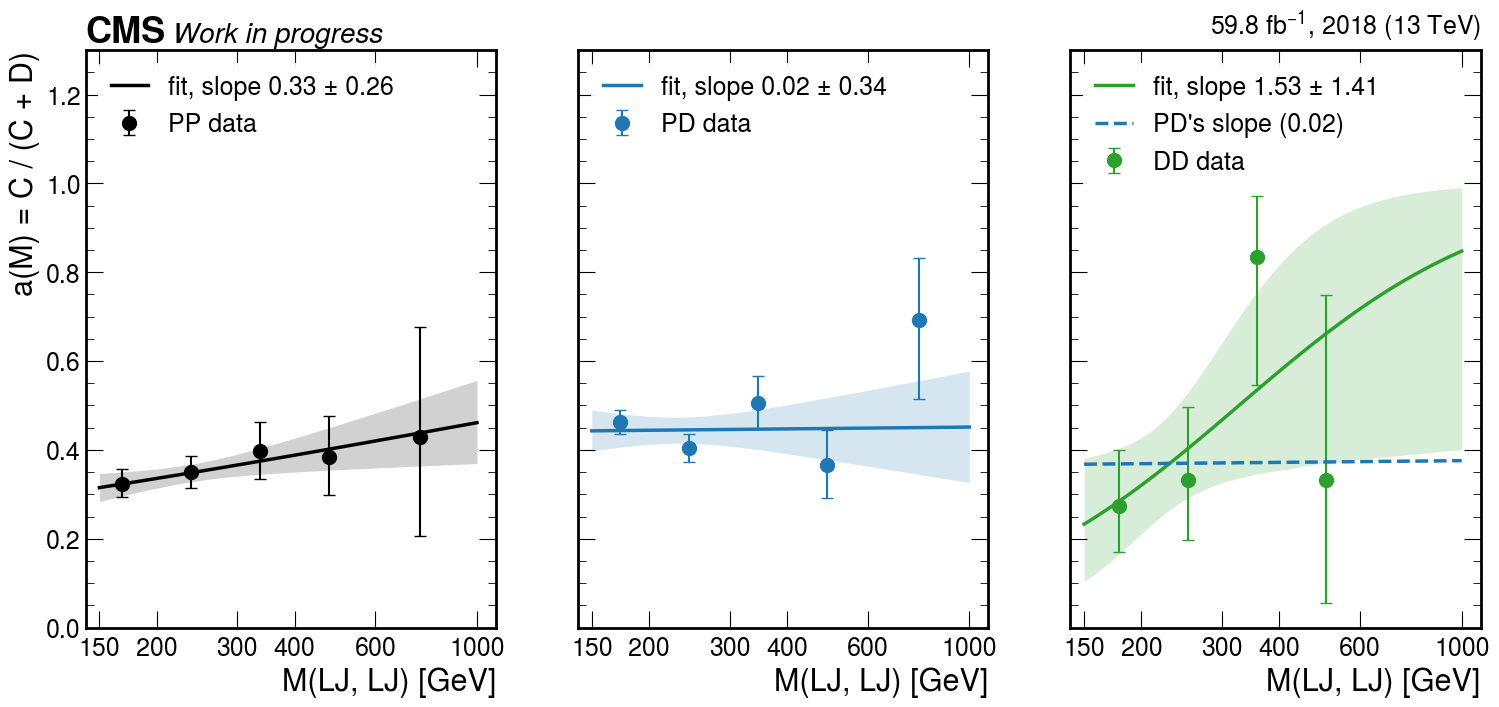

In [8]:
FITS = {p: dl.smooth_route(d2, NOMINAL, p) for p in dl.PLANES}
SHARED = dl.smooth_route(d2, NOMINAL, "DD", slope_plane="PD")
display(dl.fit_view({**FITS, "DD with PD's slope": SHARED}))
SC = dl.slope_consistency(FITS)
print(f"slopes against their weighted mean {SC['mean']:.2f}: chi2 {SC['chi2']:.1f}/{SC['ndf']}, p = {SC['p']:.2f}; separations:",
      ", ".join(f"{a}-{b} {z:+.1f}" for (a, b), z in SC["pairs"].items()))
x = FITS["DD"]["x"]
parts = FITS["DD"]["counts"][:, 1] * dl.logistic_r(FITS["DD"]["alpha"], FITS["DD"]["slope"], np.exp(x) * dl.PIVOT)
print("DD, B_w r(M_w) per bin:", np.round(parts, 1), "sum", round(float(parts.sum()), 1))
fig = dp.fit_figure(PASS, FITS, SHARED)

## 4. Route 3: a mass-flattened isolation cut

If the isolation cut is chosen per mass bin so that a(M) is the same in every bin, the one-bin
estimate is exact again (section 1), with no fit and no binning of the search region. The stored
isolation axis offers the edges 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.75 and 1. The rule used here:
keep 0.25 in the 150–200 GeV bin, which holds most of the background (the **anchor**; its a is the
target), and in every other bin take the edge whose a is closest to the target (a tie goes to the
edge nearer 0.25). Below 0.25 the band between the edge and 0.25 is a **buffer** that belongs to no
region: in DD it lies inside the hidden box, so a sideband reaching into it would be hidden; the fail
side stays at 0.25. The cut is calibrated two ways.

* **In PD's C and D** (large counts; target a = 0.462): edges 0.25, 0.3, 0.15, 0.4, 0.15 for the five bins.
  PD's a(M) is 0.46, 0.46, 0.47, 0.44, 0.67 after (χ² against a constant 2.1/4 (p = 0.71), before 8.1/4 (p = 0.09)); applied
  to DD it gives a = 0.27, 0.33, 0.80, 0.33, n/a (5.0/3 (p = 0.17); before 6.5/3 (p = 0.09)).
* **In DD's own C and D** (target 0.273): edges 0.25, 0.1, 0.15, 0.25, 0.25. DD's a(M) is 0.27, 0.23, 0.80, 0.33, n/a
  (5.9/3 (p = 0.11)). The 300–400 GeV bin of DD reads a = 0.80–0.83 at every edge: 4 of its
  5 C events sit below 0.1 and its D = 1 at or above 1, so no stored edge moves
  it; the ≥ 600 GeV bin has no C or D at any edge. At these counts DD's a(M) is compatible with a constant already with the fixed
  cut (6.5/3 (p = 0.09)); **what the available edges cannot do is move the one bin that drives the mixing
  factor, so the best achievable, in the table, leaves the mixing where it was.** Applied to PD, DD's
  edges make PD's a(M) less flat (18.7/4 (p < 0.001), against 8.1/4 (p = 0.09) with the fixed cut): they follow
  DD's fluctuations.

With the flattened cut, the one-bin estimate in DD and the mixing factor it still carries:

* PD-calibrated: B'/C'/D' = 75/16/29, **B'·C'/D' = 41.4 events** (29–57), mixing factor
  1.92 (1.06–2.20); closure in PP 1.04 ± 0.11 and PD 1.21 ± 0.10 (mixing 1.02 and 1.01);
  systematic by the rule over the validation regions of section 2 with the same edges 21% (PD);
* DD-calibrated: B'/C'/D' = 78/14/29, B'·C'/D' = 37.7 events (26–52), mixing factor
  2.02 (1.04–2.33); closure in PP 0.93 ± 0.10 and PD 1.16 ± 0.10; systematic 16% (PD).

The search region itself changes with the cut (A' is the region below each bin's edge), so these
estimates are of a different region than the one-bin 45.7 (B/C/D = 78/17/29 with the fixed
cut). The PD-calibrated edges above 0.25 (0.3 at 200–300 GeV and 0.4 at 400–600 GeV) move 3 events that were open in B into
the new search region A'; A' stays hidden. **Signal cost** (simulation, 60
2μ2e points with mediator mass 200, 500, 800, 1000 GeV, at the stored cross sections): the search-region yield
with the flattened cut over the yield with the fixed 0.25 cut is 0.99–1.01 for the PD-calibrated
cut and 0.91–1.00 for the DD-calibrated one (lowest per mediator mass: PD-calibrated 200 GeV 1.00, 500 GeV 0.99, 800 GeV 0.99, 1000 GeV 0.99;
DD-calibrated 200 GeV 0.91, 500 GeV 0.99, 800 GeV 1.00, 1000 GeV 1.00); the lowest is 2Mu2E_200GeV_0p25GeV_5p0mm (0.91). The edges between 0.1 and 0.4 cost the
signal at most 9%.

*How to read the figure:* left, the isolation edge per mass bin, fixed (grey dashed) and from each
calibration (where two choose the same edge their lines lie on top of each other); right, a(M) with
the fixed cut for PP, PD and DD (filled) and with each calibration's edges for PD and DD (open
squares PD-calibrated, open diamonds DD-calibrated), with 68% intervals.

PD-calibrated: target a = 0.462, edges (0.25, 0.3, 0.15, 0.4, 0.15); a (C/D) per bin and edge, chosen in brackets:


,bin,0.1,0.15,0.2,0.25,0.3,0.4,0.5,0.75,1
0,150-200,0.36 (114/199),0.41 (140/199),0.44 (157/199),[0.46 (171/199)],0.53 (195/175),0.58 (215/155),0.65 (240/130),0.75 (276/94),0.84 (309/61)
1,200-300,0.31 (71/155),0.35 (83/155),0.38 (95/155),0.40 (105/155),[0.46 (120/140)],0.53 (139/121),0.61 (158/102),0.79 (205/55),0.87 (227/33)
2,300-400,0.44 (33/42),[0.47 (38/42)],0.49 (40/42),0.51 (43/42),0.56 (48/37),0.59 (50/35),0.65 (55/30),0.81 (69/16),0.88 (75/10)
3,400-600,0.31 (15/33),0.31 (15/33),0.34 (17/33),0.37 (19/33),0.37 (19/33),[0.44 (23/29)],0.56 (29/23),0.73 (38/14),0.83 (43/9)
4,>=600,0.67 (8/4),[0.67 (8/4)],0.69 (9/4),0.69 (9/4),0.69 (9/4),0.77 (10/3),0.77 (10/3),0.77 (10/3),0.77 (10/3)


DD-calibrated: target a = 0.273, edges (0.25, 0.1, 0.15, 0.25, 0.25); a (C/D) per bin and edge, chosen in brackets:


,bin,0.1,0.15,0.2,0.25,0.3,0.4,0.5,0.75,1
0,150-200,0.20 (4/16),0.24 (5/16),0.24 (5/16),[0.27 (6/16)],0.27 (6/16),0.45 (10/12),0.64 (14/8),0.73 (16/6),0.82 (18/4)
1,200-300,[0.23 (3/10)],0.33 (5/10),0.33 (5/10),0.33 (5/10),0.33 (5/10),0.33 (5/10),0.47 (7/8),0.60 (9/6),0.73 (11/4)
2,300-400,0.80 (4/1),[0.80 (4/1)],0.83 (5/1),0.83 (5/1),0.83 (5/1),0.83 (5/1),0.83 (5/1),0.83 (5/1),0.83 (5/1)
3,400-600,0.00 (0/2),0.00 (0/2),0.33 (1/2),[0.33 (1/2)],0.33 (1/2),0.33 (1/2),0.33 (1/2),0.33 (1/2),0.67 (2/1)
4,>=600,–,–,–,[–],–,–,–,–,–


fixed 0.25, PP: a = [0.32 0.35 0.4  0.38 0.43], chi2 against a constant 1.8/4 (p = 0.76)
fixed 0.25, PD: a = [0.46 0.4  0.51 0.37 0.69], chi2 against a constant 8.1/4 (p = 0.09)
fixed 0.25, DD: a = [0.27 0.33 0.83 0.33  nan], chi2 against a constant 6.5/3 (p = 0.09)


,calibration,plane,a per bin,chi2 vs constant,B'/C'/D',B' C'/D',mixing factor,A',kappa
0,PD,PP,0.32 / 0.39 / 0.34 / 0.44 / 0.43,3.3 / 4 (p = 0.51),1460/206/369,815.1 (743–891),1.02 (1.00–1.09),846,1.04 ± 0.11
1,PD,PD,0.46 / 0.46 / 0.47 / 0.44 / 0.67,2.1 / 4 (p = 0.71),1326/360/414,1153.0 (1067–1244),1.01 (1.00–1.06),1391,1.21 ± 0.10
2,PD,DD,0.27 / 0.33 / 0.80 / 0.33 / –,5.0 / 3 (p = 0.17),75/16/29,41.4 (29–57),1.92 (1.06–2.20),hidden,hidden
3,DD,PP,0.32 / 0.26 / 0.34 / 0.38 / 0.43,3.8 / 4 (p = 0.43),1545/172/379,701.2 (636–770),1.02 (1.00–1.10),650,0.93 ± 0.10
4,DD,PD,0.46 / 0.31 / 0.47 / 0.37 / 0.69,18.7 / 4 (p < 0.001),1401/308/433,996.6 (920–1078),1.00 (0.99–1.07),1154,1.16 ± 0.10
5,DD,DD,0.27 / 0.23 / 0.80 / 0.33 / –,5.9 / 3 (p = 0.11),78/14/29,37.7 (26–52),2.02 (1.04–2.33),hidden,hidden


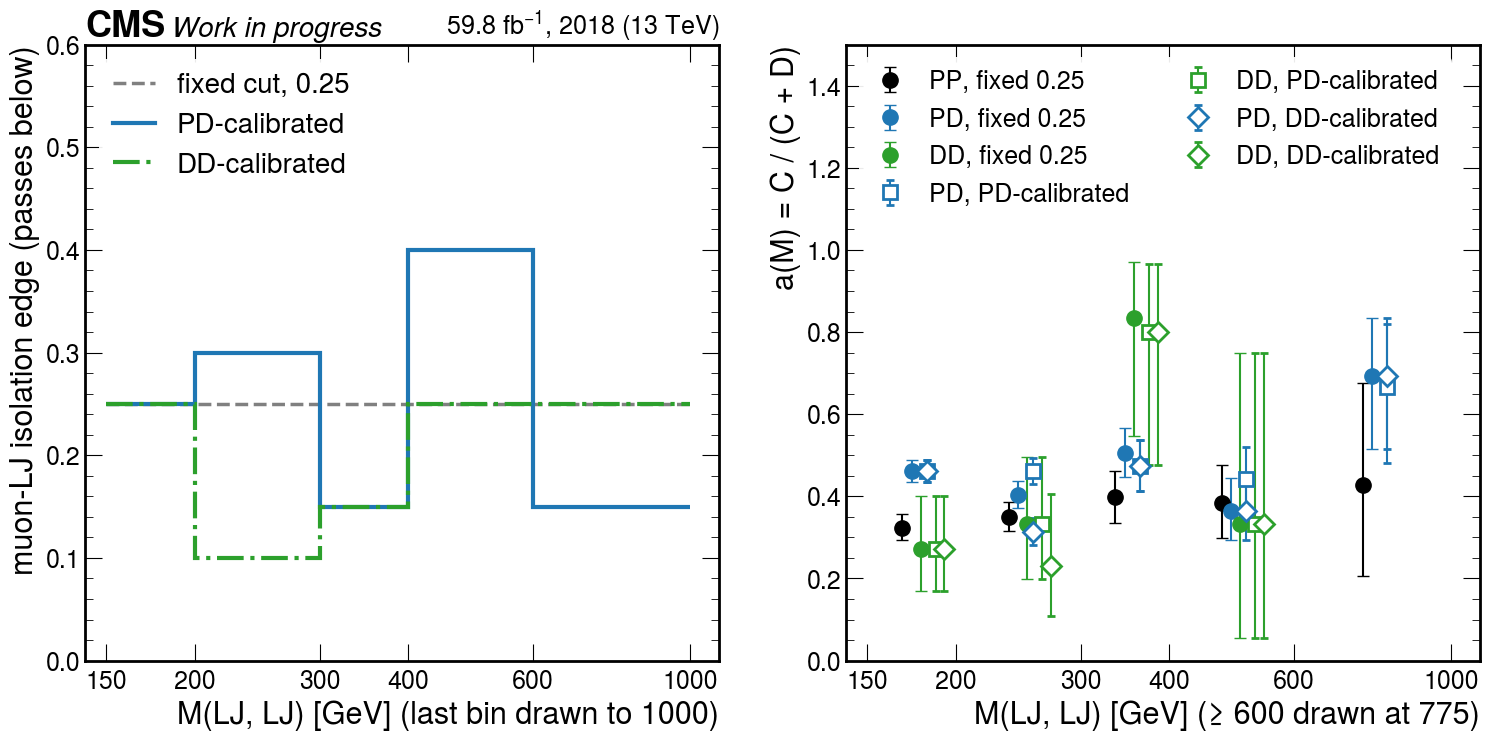

In [9]:
CHOICE, FLAT = {}, {}
for cal in ("PD", "DD"):
    cd = dl.odds_table(d2, NOMINAL, cal)
    CHOICE[cal] = dl.choose_edges(cd)
    print(f"{cal}-calibrated: target a = {CHOICE[cal]['target']:.3f}, edges {CHOICE[cal]['edges']}; a (C/D) per bin and edge, chosen in brackets:")
    display(dl.odds_view(cd, CHOICE[cal]))
    for p in dl.PLANES:
        FLAT[(cal, p)] = dl.flat_route(d2, NOMINAL, p, dl.FIVE, CHOICE[cal]["edges"])
BEFORE = {p: dl.flatness(CD[p]) for p in dl.PLANES}
for p, fl in BEFORE.items():
    print(f"fixed 0.25, {p}: a = {np.round(fl['a'], 2)}, chi2 against a constant {fl['chi2']:.1f}/{fl['ndf']} (p = {fl['p']:.2f})")
display(dl.flat_view(FLAT))
fig = dp.flatten_figure({f"{c}-calibrated": CHOICE[c]["edges"] for c in CHOICE}, BEFORE,
                        {(f"{c}-calibrated", p): FLAT[(c, p)]["flatness"] for c in CHOICE for p in ("PD", "DD")})

In [10]:
SIG_NAMES = [n for n in sorted(os.path.basename(p)[: -len(".coffea")] for p in tl.sample_paths(BASE, "signal")
                                if os.path.basename(p).startswith("2Mu2E_")) if nl.mediator_mass(n) >= 200]
COST = dl.signal_cost(BASE, SIG_NAMES, NOMINAL, dl.FIVE, {f"{c}-calibrated": CHOICE[c]["edges"] for c in CHOICE})   # simulation
print(f"{len(SIG_NAMES)} 2mu2e signal points: search-region yield with the flattened cut over the fixed 0.25 cut, per mediator mass")
display(dl.cost_summary(COST, [f"{c}-calibrated" for c in CHOICE]))

60 2mu2e signal points: search-region yield with the flattened cut over the fixed 0.25 cut, per mediator mass


,mediator mass [GeV],points,PD-calibrated,DD-calibrated
0,200,15,1.00–1.00,0.91–1.00
1,500,15,0.99–1.01,0.99–1.00
2,800,15,0.99–1.00,1.00–1.00
3,1000,15,0.99–1.00,1.00–1.00


## 5. Comparison and proposal

One row per route, with the one-bin estimate of `nominal.ipynb` as the baseline. "Mixing still
carried" is the mixing factor the estimate does not remove (for route 1 in two windows, the
five-bin sum over the two-window one); the closure is A over the route's prediction in PP and PD
(the baseline and route 1: Poisson bootstrap of the four counts; route 2: refitted toys; route 3:
Clopper–Pearson-based intervals of the summed regions). The systematic is the rule of
`nominal.ipynb` section 8 over the same 11 validation regions for every route (those of
section 2 that are not a sub-population of a plane), each region's κ computed with the route's own
method (per window for route 1); for the baseline it reproduces the 20% (PD) of `nominal.ipynb`.
The second table lists those κ, "*" marking one not measured to 20% and brackets the one that sets
the systematic. In the first table, "free choices" counts what the analyst sets (bin boundaries, a functional form, an edge per bin),
"fitted parameters" what the data set; "rests on" the smallest count that drives the number; the
signal yield ratio is the search-region yield over the fixed cut's, min–max over the 60 points.

In [11]:
REC = dl.comparison(d2, NOMINAL, {c: CHOICE[c]["edges"] for c in CHOICE}, COST)
display(dl.comparison_view(REC))
display(dl.readings_view(REC))

,route,DD estimate (68% interval),mixing still carried,closure PP,closure PD,systematic by the rule,free choices,fitted parameters,systematics carried,rests on,signal yield ratio,still to validate
0,one bin (nominal.ipynb),45.7 (32–63),1.62 between the windows (1.16–3.13); 2.06 over the bins (1.08–2.35),0.97 -0.09 +0.10,1.20 -0.09 +0.10,20% (PD); the mixing not covered,0,0,1 + the mixing caveat,D = 29,1,the mixing factor in DD
1,"1, stratified, 2 windows",74.0 (47–155),1.27 inside the windows (the five-bin sum over this one),0.94 ± 0.10,1.18 ± 0.10,31% / 34% per bin; 33% on the sum,1,0,2,D = 3,1,kappa per bin with a displaced LJ above 300 GeV
2,"1, stratified, 5 bins (≥ 600 merged)",94.0 (43–114),inside the bins: not measurable (C and D of DD are empty above 600 GeV),0.93 -0.12 +0.09,1.18 -0.12 +0.09,33% / 41% / none / none,3,0,"4, 2 without a qualifying region",D = 1,1,kappa per bin with a displaced LJ; no region measures it above 300 GeV
3,"2, logistic a(M), DD's own fit",72.1 (39–308),absorbed by the fit,0.94 ± 0.10,1.19 -0.15 +0.16,19% (PD) + the fit form,1,2 per plane,"2 (closure, fit form)",D = 1 at 300–400 GeV sets the slope; B = 4 at ≥ 600 GeV is extrapolated,1,the form (PD's fit: deviance 8.1/3)
4,"2, logistic a(M), PD's slope",45.8 (28–72),absorbed by the fit,0.97 ± 0.10,1.19 -0.15 +0.16,19% (PD) + 57% for the slope (DD's own gives 72),1,1 in DD + PD's slope,"2 (closure, slope transfer)",C + D = 46 in DD for the intercept,1,that DD's slope is PD's
5,"3, flattened cut, PD-calibrated",41.4 (29–57),1.92 (1.06–2.20),1.04 ± 0.11,1.21 ± 0.10,21% (PD) + the calibration transfer,5,0,"2 (closure, calibration)",D = 1 in a bin; D = 29 summed,0.99–1.01,a flat a(M) in DD; a new search region
6,"3, flattened cut, DD-calibrated",37.7 (26–52),2.02 (1.04–2.33),0.93 ± 0.10,1.16 ± 0.10,16% (PD) + the calibration transfer,5,0,"2 (closure, calibration)",D = 1 in a bin; D = 29 summed,0.91–1.00,a flat a(M) in DD; a new search region


,region,one bin,1: 150-300,1: ≥ 300,"2, own slope","2, PD's slope","3, PD-calibrated","3, DD-calibrated"
0,PP,0.97 ± 0.10,1.08 ± 0.13,0.67 -0.15 +0.15 *,0.94 ± 0.10,0.97 ± 0.10,1.04 ± 0.11,0.93 ± 0.10
1,PD,[1.20 ± 0.10],[1.31 ± 0.12],0.87 ± 0.17,[1.19 -0.15 +0.16],[1.19 -0.15 +0.16],[1.21 ± 0.10],[1.16 ± 0.10]
2,DP,1.02 -0.41 +0.48 *,0.87 -0.44 +0.50 *,not measured *,1.08 -0.44 +0.57 *,1.01 -0.39 +0.66 *,1.10 -0.45 +0.51 *,0.87 -0.36 +0.43 *
3,"DD, egamma iso ≥ 0.5",0.67 ± 0.60 *,0.67 ± 0.62 *,n/a,0.77 -0.65 +0.47 *,0.66 -0.34 +0.63 *,0.78 ± 0.69 *,not measured *
4,"DD, egamma iso ≥ 0.75",not measured *,not measured *,n/a,not measured *,2.74 -1.99 +0.97 *,not measured *,not measured *
5,"DD, egamma iso ≥ 1",n/a,n/a,n/a,n/a,n/a,n/a,n/a
6,"DD, egamma iso 0.5–1",0.71 ± 0.71 *,not measured *,n/a,0.83 -0.83 +0.60 *,not measured *,0.94 ± 0.94 *,not measured *
7,V1,0.97 ± 0.10,1.08 ± 0.13,0.67 -0.15 +0.15 *,0.94 ± 0.10,0.97 ± 0.10,1.04 ± 0.11,0.93 ± 0.10
8,V5,1.05 ± 0.08,1.16 ± 0.10,0.70 ± 0.13,1.03 ± 0.10,1.05 ± 0.10,1.11 ± 0.08,1.00 ± 0.08
9,V6,1.03 ± 0.07,1.15 ± 0.09,[0.66 ± 0.11],1.01 ± 0.08,1.03 ± 0.09,1.09 ± 0.08,0.98 ± 0.07


**What the table says.** No route reduces PD's non-closure: PD's closure is 1.16–1.21 in every row.
That non-closure is not mass mixing, since PD's own mixing factor is 1.010 with two windows and 1.015 with five bins; PD's κ does vary with
the mass (1.31 ± 0.12 below 300 GeV, 0.87 ± 0.17 above), which is what route 1's per-window systematics
see. What the routes differ in is how they treat DD's rise of a(M) above 300 GeV, which rests on
D = 1 at 300–400 GeV. Route 1 in five bins and route 2 with DD's own slope take it at face value and
inherit its statistics (five bins: 94.0, 43–114; smooth: 72.1, 39–308). Route 2 with PD's
slope assumes it away and lands near the one-bin value (45.8). Route 3 leaves it in place: its
mixing factor stays 1.92 (1.06–2.20), and its lower estimates (41.4 and 37.7) come from a changed
region (B/C/D = 78/17/29 becomes B'/C'/D' = 75/16/29 with the PD-calibrated edges), not from
removing the rise; the PD-calibrated edges also move 3 open B events into the hidden A'.

**Proposal to the group.** We propose route 1 at the granularity of two mass windows, 150–300 GeV and
≥ 300 GeV: estimate the background in each window from that window's own B, C and D, and give each
window its own closure systematic by the rule of `nominal.ipynb` section 8. It is the simplest
analysis that removes the mixing between the windows: no fit, no new cut, and one free choice, the
split at 300 GeV, which `binning.ipynb` makes for sensitivity anyway (a factor 2.6 in the expected
limit at 800 GeV from that split alone). It is the only binned route in which the rule yields a
systematic in every bin: 31% below 300 GeV (set by PD) and 34% above (set by V6). The
numbers this rests on: the two-window estimate 74 events (68% interval 47–155; 22 below
300 GeV and 52 above, 25–130), its closure in the open planes (PP 0.94 ± 0.10, PD 1.18 ± 0.10, against PP 0.97 -0.09 +0.10, PD 1.20 -0.09 +0.10 in
one bin), the per-window systematics just quoted, and the five-bin and smooth routes' dependence on
the one D event at 300–400 GeV. Its cost is statistical: the high window rests on D = 3, and
its interval spans a factor 5.2.

Two routes tie on simplicity with it. The one-bin estimate with the mixing factor added as a
systematic also carries two systematics and no fitted parameter; it would carry the mixing as a
one-sided +62% resting on the same 3 events, where the two-window estimate carries it as
the statistical error of the high window. Route 2 with PD's slope also carries two systematics (the
closure, 19% (PD), and the slope transfer, 57%), plus a fit whose form PD does not
support (deviance 8.1/3 (p = 0.04)). **What decides between them is D of the search plane above 300 GeV**
(3 events now, 1 at 300–400 GeV): it sets the two-window estimate, the mixing factor and the
slope difference (1.0 standard deviations between DD and PD). The open bands of the search
plane (section 1d) hold no C or D event above 300 GeV and cannot help. DD's window-to-window
isolation odds differ from PD's by 1.7 standard deviations now; at the present rates two
standard deviations need about 4 D events above 300 GeV (1.3 times the data) and three about
9 (3.0 times). Route 3 is not proposed: it changes the search region, its five edges are free
choices, and it leaves DD's mixing where it was.

## Appendix: reproducibility

The data are read only through `transfer_lib.summed_cubes(BASE, "data", prefix="abcd8d")`, which sums
the merged 8D histograms and sets the hidden box (iso0<0.25 iso1<0.5 mass>=150 dphi>=2.4 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]) to NaN before anything is cached or
returned; A of DD above 150 GeV is NaN in every mass bin and is never read. The signal-cost table of
section 4 reads the signal histograms one point at a time (`decorrelation_lib.signal_cost`;
simulation is never hidden). Code: `decorrelation_lib.py` (the identity, a(M) and b(M), the mixing
factor and its bootstrap, the shape test, the three routes, the comparison), `decorrelation_plots.py`
(the figures), `_build_mass_decorrelation.py` (writes this notebook and computes every number in its
text with the same functions and seeds), `test_decorrelation_lib.py` (tests on synthetic
populations and histograms). On the LPC: `python _build_mass_decorrelation.py` then
`jupyter nbconvert --to notebook --execute --inplace mass_decorrelation.ipynb` in `sidm_venv`.